## Comparison of Tony Grove RS output to GAMUT

In [1]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from buildforcing.datasets import PNNLSnotel
import os

In [2]:
# Define environment for paths
path_env = 'desktop' # 'desktop' or 'alpine'

In [3]:
# Configure environment
if path_env == 'desktop':
    output_path = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    snotel_path = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    gamut_path = 'C:/Users/clmbn/NMT_PhD/data/gamut/' #desktop
elif path_env == 'alpine':
    output_path = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    snotel_path = r'/projects/ccox1@xsede.org/data/snotel/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [4]:
# Run configuration
snotel_site = 'Tony Grove RS'  #Use the Snotel name
forcings = 's00000000'
run_config = 'v0.1'

In [5]:
# Convert name for output paths
site = snotel_site.replace(' ','').lower()
print(f'Output site: {site}')

Output site: tonygrovers


Load the 'Land Daily' diagnostic from output.

In [6]:
output_folder = os.path.join(output_path,f'{site}/{site}_{forcings}_{run_config}/history/')

In [7]:
# Find the land daily file name in folder and open
land_daily=None
for filename in os.listdir(output_folder):
    if filename.endswith(".land_daily.nc"):
        land_daily = xr.open_dataset(output_folder + filename)
if not land_daily:
    print('Error: no land daily found')

### Notes on timezone:
- Model output is in UTC, but it is a daily average set to noon. This means that a timezone shift to mountain time will not change the date.
- Since there is no change in date from timezone and the data is daily, I won't convert the timezone of the model output.

In [8]:
# Extract snow data from Land Daily dataset
snow_data = land_daily[['snow','snow_depth','snow_density']].isel(grid_index=0).to_dataframe()
snow_data.index = snow_data.index.to_datetimeindex()

# Convert index to America/Denver timezone
# snow_data.index = snow_data.index.tz_localize('UTC').tz_convert('America/Denver')

C:\Users\clmbn\AppData\Local\Temp\ipykernel_3752\4036538477.py:3: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  snow_data.index = snow_data.index.to_datetimeindex()


In [9]:
# Set time of model output to midnight
snow_data.index = snow_data.index - pd.Timedelta(hours=12)

## Load the GAMUT data

In [10]:
from datetime import timedelta, timezone

def gamut_soil(depth) -> pd.Series:
    """
    Load GAMUT soil data for a given depth.
    """
    # depth options are 5, 50, and 100 cm
    if depth not in [5, 50, 100]:
        raise ValueError("Depth must be one of [5, 50, 100] cm.")
    
    # First find in the file the row that starts with 'LocalDateTime'
    with open(os.path.join(gamut_path, 'tonygrovers', f'LR_TG_C_SoilTemp_{depth}cm_Avg_SourceID_1_QC_1.csv')) as f:
        for i, line in enumerate(f):
            if line.startswith('LocalDateTime'):
                skiprows = i
                break
    
    soil_temp = pd.read_csv(
        os.path.join(gamut_path, 'tonygrovers', f'LR_TG_C_SoilTemp_{depth}cm_Avg_SourceID_1_QC_1.csv'),
        skiprows= skiprows,
        )

    # Create datetime index from LocalDateTime
    soil_temp.index = pd.DatetimeIndex(
        pd.to_datetime(soil_temp['LocalDateTime'], format='%Y-%m-%d %H:%M:%S')
    )

    # Localize the data to have a fixed UTC offset of -7 hours
    utc_offset = timezone(timedelta(hours=-7))
    soil_temp.index = soil_temp.index.tz_localize(utc_offset)

    data_column = f'SoilTemp_{depth}cm_Avg'
    output_series = soil_temp[data_column].rename('soil_temp')

    return output_series

In [11]:
gamut_5cm_soilT = gamut_soil(5)
gamut_5cm_soilT = gamut_5cm_soilT.replace(-9999, pd.NA)  # Replace -9999 with NaN

In [12]:
# Resample soil temperature to daily mean
gamut_5cm_soilT_daily = gamut_5cm_soilT.resample('D').mean()

### Load the model soil T data

In [13]:
# Get the first time coordinate from the daily dataset
model_start_str = land_daily['time'].to_index()[0].strftime('%Y-%m-%d 12:00')
model_end_str = land_daily['time'].to_index()[-1].strftime('%Y-%m-%d 12:00')
model_start = pd.Timestamp(model_start_str)

# Create a date range for the model index
# Adjust the end date to account for the leap year in 1900
if model_start < pd.Timestamp('1900-03-01'):
    model_end = pd.Timestamp(model_end_str) + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
else:
    model_end = pd.Timestamp(model_end_str) 

output_index_gregorian = pd.date_range(start=model_start, end=model_end, freq='D')

In [14]:
# Extract soil temperatures
def extract_soil_data(soil_var) -> pd.DataFrame:
    soil_data = land_daily[[soil_var]].isel(grid_index=0).to_dataframe()
    soil_data_df = soil_data.reset_index().pivot(index='time', columns='zfull_soil', values=soil_var)
    soil_data_df.columns.name = 'Depth'
    soil_data_df.index = output_index_gregorian
    soil_data_df.columns = [f"{col:03.2f}" for col in soil_data_df.columns]
    return soil_data_df

soil_T = extract_soil_data('soil_T')

# Convert soil temperature to Celsius
soil_T = soil_T - 273.15  # Convert from Kelvin to Celsius


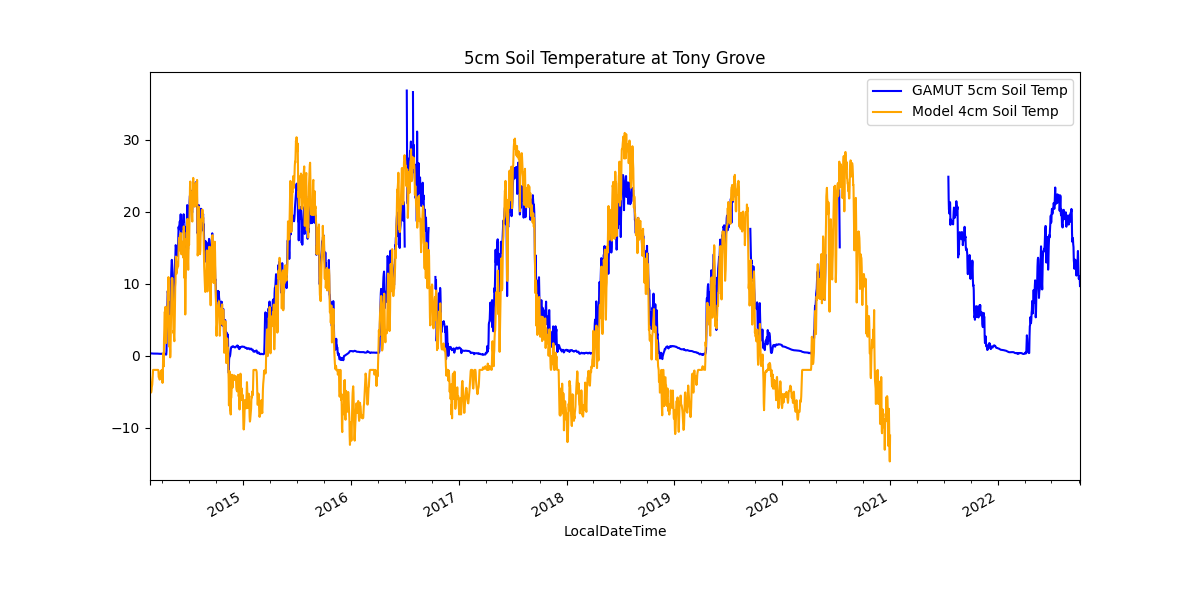

In [16]:
# Plot 5cm soil temperatures
plt.figure(figsize=(12, 6))
gamut_5cm_soilT_daily.plot(label='GAMUT 5cm Soil Temp', color='blue')
soil_T['0.04'].plot(label='Model 4cm Soil Temp', color='orange')
plt.title('5cm Soil Temperature at Tony Grove')
plt.legend()

Load the Snotel data

In [ ]:
snotel = PNNLSnotel(snotel_site, snotel_path)

In [ ]:
snotel_data = snotel.data

In [ ]:
# Remove timezone from Snotel data index so it can be compared with model data
snotel_data.index = snotel_data.index.tz_localize(None)

Comparison plots

In [ ]:
fig, axs = plt.subplots(1, 1, figsize=(12, 6))
snow_data['snow'].plot(ax=axs, label='Model Snow Water Equivalent', color='red')
snotel_data['swe_mm'].plot(ax=axs, label='SNOTEL Snow Water Equivalent', color='blue')
axs.legend()
plt.title(f'{snotel_site} nldas cm')

In [ ]:
plt.savefig('quemazon_test.png')

### Calculate the difference between the model and Snotel data

In [ ]:
snow_combined = pd.merge(snotel_data['swe_mm'], snow_data['snow'], how='inner', left_index=True, right_index=True)
snow_combined.columns = ['snotel_swe', 'model_swe']

I am seeing small negative values for SWE model output, not sure what is going on.

In [ ]:
# Calculate water year for each date
def water_year(date):
    if date.month < 10:
        return date.year
    else:
        return date.year + 1
    
snow_combined['water_year'] = snow_combined.index.to_series().apply(water_year)


In [ ]:
# Calculate model - Snotel difference
snow_combined['swe_diff'] = snow_combined['model_swe'] - snow_combined['snotel_swe']

In [ ]:
# Calculate RMSE by water year
rmse_by_wateryear = snow_combined.groupby('water_year')['swe_diff'].apply(
    lambda x: (x ** 2).mean() ** 0.5
)

In [ ]:
print(rmse_by_wateryear.tail())

RMSE:
- Tonygrove on the order of 45
- Quemazon has many more datapoints, but RMSE looks similar, more spread?

